# Streaming Recommender at Scale: Benchmark Results & Bias-Utility Tradeoffs

**Project**: Recommender at Scale: Latency, Cost, and Popularity Bias  
**Engines**: Apache Spark Structured Streaming vs. Apache Flink (PyFlink)  
**Dataset**: Microsoft News Dataset (MIND-small)  

> **Note on Reproducibility**: All figures, tables, and statistics in this notebook are dynamically loaded from benchmark output files (data/processed/, logs/probe_report.csv). No values are hardcoded.

In [1]:
import os
import json
from pathlib import Path
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'figure.autolayout': True, 'font.size': 11})

ROOT = Path('..') if Path('../data').exists() else Path('.')
PROBE_PATH = ROOT / 'logs' / 'probe_report.csv'
MATRIX_PATH = ROOT / 'data' / 'processed' / 'analysis' / 'matrix_summary.csv'
RERANK_PATH = ROOT / 'data' / 'processed' / 'analysis' / 'rerank_overhead.csv'
BIAS_PATH = ROOT / 'data' / 'processed' / 'bias_summary.csv'
BOOTSTRAP_SUMMARY = ROOT / 'data' / 'processed' / 'analysis' / 'bootstrap_summary.json'
BOOTSTRAP_CIS = ROOT / 'data' / 'processed' / 'analysis' / 'bootstrap_cis.json'
BOOTSTRAP_PATH = BOOTSTRAP_SUMMARY if BOOTSTRAP_SUMMARY.exists() else BOOTSTRAP_CIS

print('Loading data files...')
probe_df = pd.read_csv(PROBE_PATH) if PROBE_PATH.exists() else None
matrix_df = pd.read_csv(MATRIX_PATH) if MATRIX_PATH.exists() else None
rerank_df = pd.read_csv(RERANK_PATH) if RERANK_PATH.exists() else None
bias_df = pd.read_csv(BIAS_PATH) if BIAS_PATH.exists() else None
bootstrap_data = json.loads(BOOTSTRAP_PATH.read_text()) if BOOTSTRAP_PATH.exists() else None

if probe_df is not None:
    probe_clean = probe_df[
        (probe_df['status'] != 'DEBUG') &
        ~((probe_df['config'] == 'spark-1s') & (probe_df['target_rate'] == 4000))
    ].copy()
    print(f'Probe rows loaded: {len(probe_clean)}')
if matrix_df is not None:
    print(f'Matrix summary rows loaded: {len(matrix_df)}')
if rerank_df is not None:
    print(f'Rerank overhead rows loaded: {len(rerank_df)}')
if bias_df is not None:
    print(f'Bias summary rows loaded: {len(bias_df)}')
if bootstrap_data is not None:
    print(f'Bootstrap CIs loaded: {len(bootstrap_data.get("bootstrap_cis", []))} entries')
else:
    print('Bootstrap CIs: NOT RUN')


Loading data files...
Probe rows loaded: 41
Matrix summary rows loaded: 14
Rerank overhead rows loaded: 20
Bias summary rows loaded: 42
Bootstrap CIs loaded: 66 entries


## 1. End-to-End Latency vs. Input Rate

Measures Kafka LogAppendTime-to-LogAppendTime end-to-end latency across throughput tiers (100 to 4,000 ev/s) from the single-variable capacity probe.

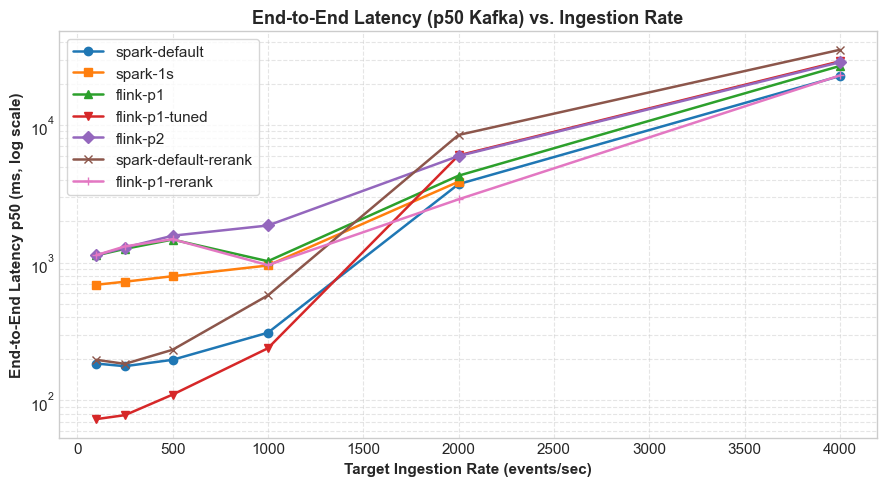

In [2]:
if probe_clean is not None:
    fig, ax = plt.subplots(figsize=(9, 5))
    configs = probe_clean['config'].unique()
    markers = {'spark-default': 'o', 'spark-1s': 's', 'flink-p1': '^', 'flink-p1-tuned': 'v', 'flink-p2': 'D', 'spark-default-rerank': 'x', 'flink-p1-rerank': '+'}
    for cfg in configs:
        sub = probe_clean[probe_clean['config'] == cfg].sort_values('target_rate')
        marker = markers.get(cfg, 'o')
        ax.plot(sub['target_rate'], sub['latency_p50_kafka'], marker=marker, label=cfg, linewidth=1.8, markersize=6)
    ax.set_yscale('log')
    ax.set_xlabel('Target Ingestion Rate (events/sec)', fontweight='bold')
    ax.set_ylabel('End-to-End Latency p50 (ms, log scale)', fontweight='bold')
    ax.set_title('End-to-End Latency (p50 Kafka) vs. Ingestion Rate', fontsize=13, fontweight='bold')
    ax.legend(loc='upper left', frameon=True)
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.show()
else:
    print('NOT FOUND: logs/probe_report.csv')


## 2. Resource Efficiency: CPU Seconds per 1,000 Events

Evaluates CPU consumption per 1,000 processed events across engines and configurations at 1,000 and 2,000 ev/s (3 replicated runs per condition with 60s measurement windows).

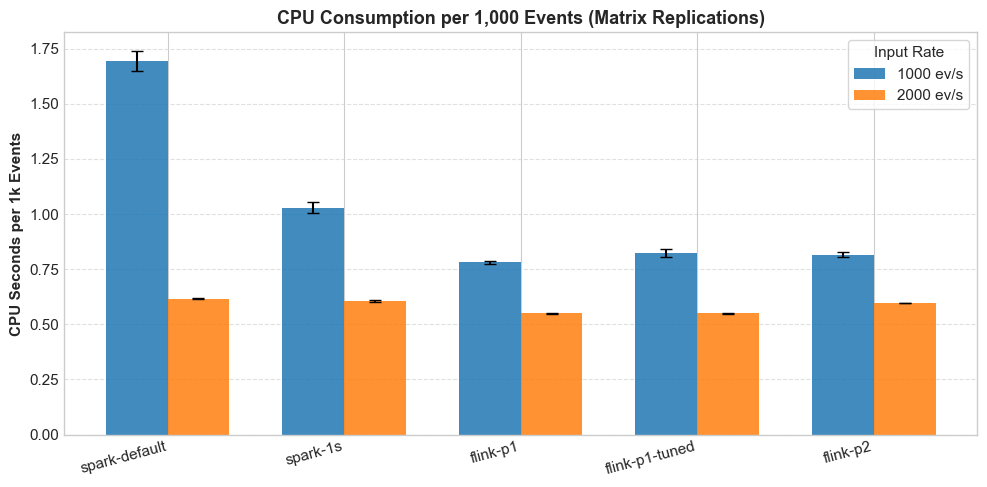

In [3]:
if matrix_df is not None:
    fig, ax = plt.subplots(figsize=(10, 5))
    rates = [1000, 2000]
    configs = [c for c in matrix_df['config'].unique() if not c.endswith('-rerank')]
    x = np.arange(len(configs))
    width = 0.35

    for i, r in enumerate(rates):
        sub = matrix_df[matrix_df['rate'] == r].set_index('config')
        means = [sub.loc[c, 'cpu_per_1k_events_mean'] if c in sub.index else 0 for c in configs]
        stds = [sub.loc[c, 'cpu_per_1k_events_std'] if c in sub.index else 0 for c in configs]
        ax.bar(x + i*width - width/2, means, width, yerr=stds, capsize=4, label=f'{r} ev/s', alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels(configs, rotation=15, ha='right')
    ax.set_ylabel('CPU Seconds per 1k Events', fontweight='bold')
    ax.set_title('CPU Consumption per 1,000 Events (Matrix Replications)', fontsize=13, fontweight='bold')
    ax.legend(title='Input Rate', frameon=True)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    plt.show()
else:
    print('NOT FOUND: data/processed/analysis/matrix_summary.csv')


## 3. Backlog Accumulation at Saturation (2,000 ev/s)

Under sustained 2,000 ev/s ingestion, processing engines exceed single-node throughput capacity, causing queueing in Kafka. This chart compares the resulting backlog at the end of the 60s window.

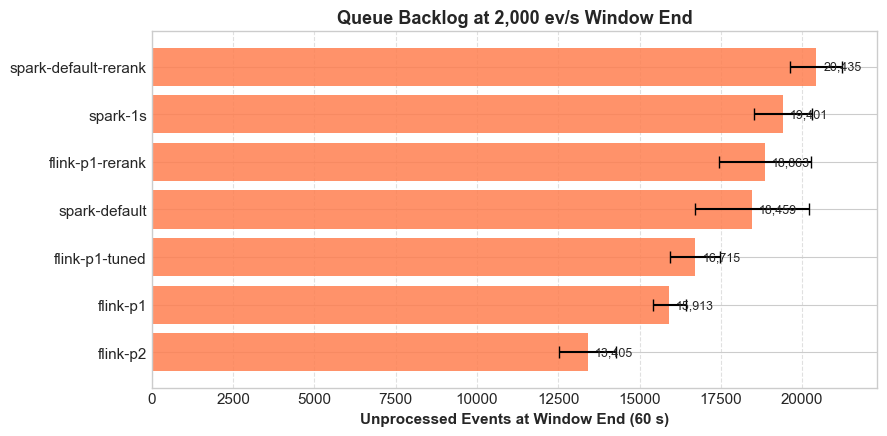

In [4]:
if matrix_df is not None:
    sub2k = matrix_df[matrix_df['rate'] == 2000].sort_values('backlog_at_window_end_mean')
    fig, ax = plt.subplots(figsize=(9, 4.5))
    bars = ax.barh(sub2k['config'], sub2k['backlog_at_window_end_mean'],
                   xerr=sub2k['backlog_at_window_end_std'], capsize=4, color='coral', alpha=0.85)
    ax.set_xlabel('Unprocessed Events at Window End (60 s)', fontweight='bold')
    ax.set_title('Queue Backlog at 2,000 ev/s Window End', fontsize=13, fontweight='bold')
    ax.grid(axis='x', linestyle='--', alpha=0.6)
    for bar in bars:
        width = bar.get_width()
        ax.annotate(f'{int(width):,}', xy=(width, bar.get_y() + bar.get_height()/2),
                    xytext=(5, 0), textcoords='offset points', ha='left', va='center', fontsize=9)
    plt.show()
else:
    print('NOT FOUND: matrix_summary.csv')


## 4. Popularity-Bias Mitigation: Pareto Frontier

Trade-off between publisher exposure deviation (Exposure L1 distance from target share) and recommendation utility (Served nDCG@5) across $\lambda \in [0.0, 5.0]$ across 6 publisher mappings.

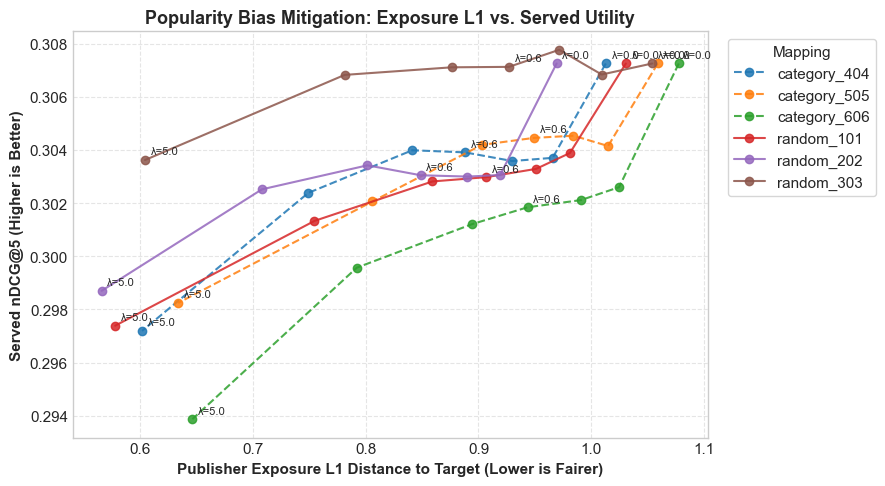

In [5]:
if bias_df is not None:
    fig, ax = plt.subplots(figsize=(9, 5))
    mappings = bias_df['mapping'].unique()
    for m in mappings:
        sub = bias_df[bias_df['mapping'] == m].sort_values('lambda')
        linestyle = '-' if m.startswith('random') else '--'
        ax.plot(sub['exposure_l1'], sub['ndcg_at_5_served'], marker='o', label=m, linestyle=linestyle, alpha=0.85)
        for _, r in sub.iterrows():
            if r['lambda'] in [0.0, 0.6, 5.0]:
                ax.annotate(f"λ={r['lambda']}", (r['exposure_l1'], r['ndcg_at_5_served']),
                            textcoords='offset points', xytext=(4, 4), fontsize=8)
    ax.set_xlabel('Publisher Exposure L1 Distance to Target (Lower is Fairer)', fontweight='bold')
    ax.set_ylabel('Served nDCG@5 (Higher is Better)', fontweight='bold')
    ax.set_title('Popularity Bias Mitigation: Exposure L1 vs. Served Utility', fontsize=13, fontweight='bold')
    ax.legend(title='Mapping', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
    ax.grid(True, linestyle='--', alpha=0.5)
    plt.show()
else:
    print('NOT FOUND: data/processed/bias_summary.csv')


## 5. Fair Reranker Runtime Overhead

Percentage change in streaming metrics when enabling greedy fair re-ranking ($\lambda=0.6$) versus the unconstrained base scorer.

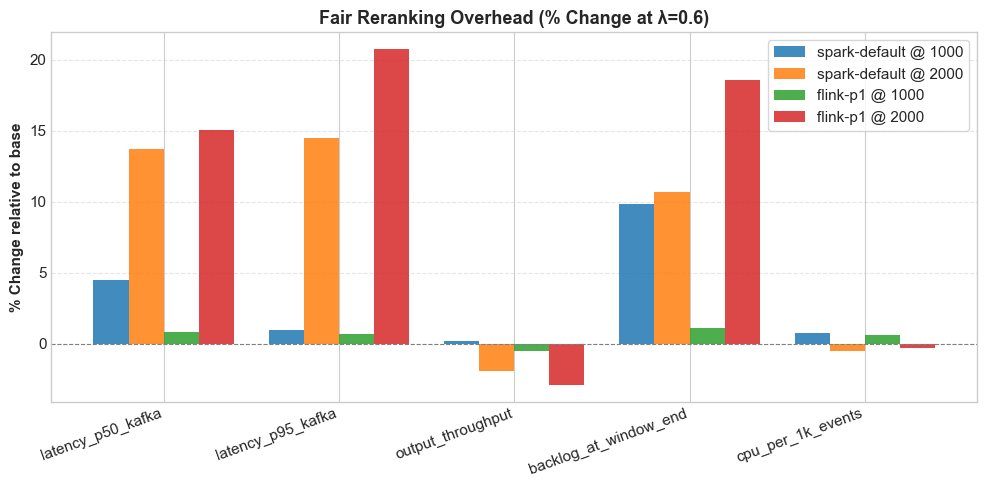

In [6]:
if rerank_df is not None:
    fig, ax = plt.subplots(figsize=(10, 5))
    metrics = ['latency_p50_kafka', 'latency_p95_kafka', 'output_throughput', 'backlog_at_window_end', 'cpu_per_1k_events']
    engines = rerank_df['engine'].unique()
    rates = [1000, 2000]
    plot_data = []
    labels = []
    for eng in engines:
        for r in rates:
            sub = rerank_df[(rerank_df['engine'] == eng) & (rerank_df['rate'] == r)]
            row_dict = sub.set_index('metric')['pct_change'].to_dict()
            plot_data.append([row_dict.get(m, 0.0) for m in metrics])
            labels.append(f'{eng} @ {r}')
    x = np.arange(len(metrics))
    n_bars = len(plot_data)
    width = 0.8 / n_bars
    for i, (vals, lbl) in enumerate(zip(plot_data, labels)):
        ax.bar(x + i*width - 0.4 + width/2, vals, width, label=lbl, alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, rotation=20, ha='right')
    ax.set_ylabel('% Change relative to base', fontweight='bold')
    ax.set_title('Fair Reranking Overhead (% Change at λ=0.6)', fontsize=13, fontweight='bold')
    ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
    ax.legend(frameon=True)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()
else:
    print('NOT FOUND: rerank_overhead.csv')


## 6. Offline Metric Bootstrap Confidence Intervals

Bootstrap confidence intervals (1,000 resamples of impression sessions) for exposure L1, Gini, and served nDCG@5.

Total bootstrap CI records: 66
         mapping      lambda                       metric  estimate  bootstrap_mean       low      high
0   category_404         0.0                  exposure_l1  1.012772        1.012866  1.009622  1.016151
1   category_404         0.0               publisher_gini  0.676441        0.676480  0.674985  0.678016
2   category_404         0.0             ndcg_at_5_served  0.307251        0.307293  0.304853  0.309741
3   category_404         0.0                          auc  0.617760        0.617775  0.615658  0.619998
4   category_404         0.0                   ndcg_at_10  0.369877        0.369913  0.367570  0.372205
5   category_404         5.0                  exposure_l1  0.602081        0.602089  0.598609  0.605654
6   category_404         5.0               publisher_gini  0.446428        0.446537  0.444552  0.448486
7   category_404         5.0             ndcg_at_5_served  0.297194        0.297200  0.294806  0.299915
8   category_404         5.0     

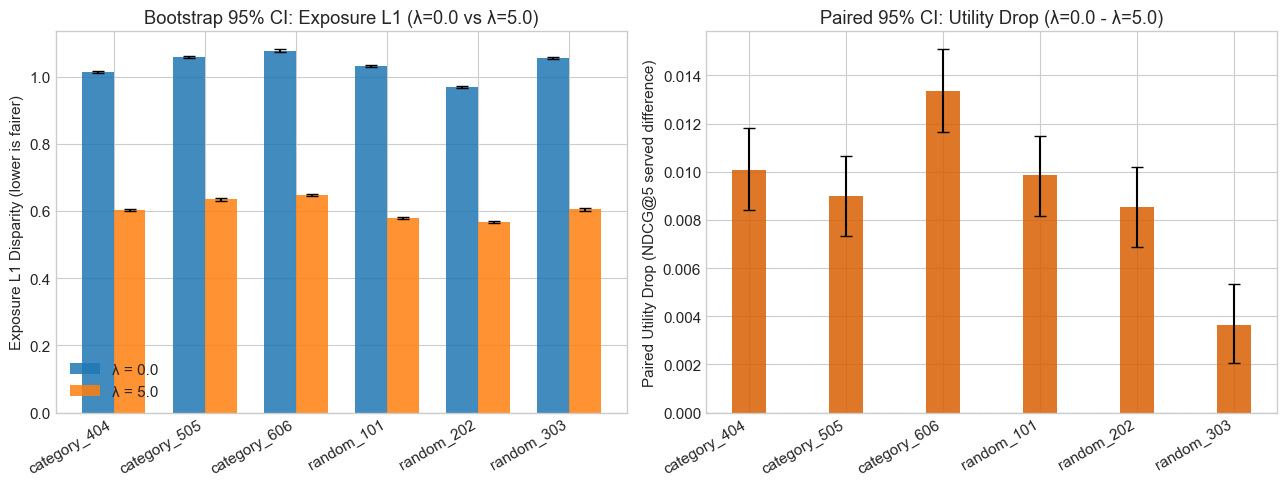

In [7]:
if bootstrap_data is not None:
    cis = bootstrap_data.get('bootstrap_cis', [])
    cis_df = pd.DataFrame(cis)
    display_cols = ['mapping', 'lambda', 'metric', 'estimate', 'bootstrap_mean', 'low', 'high']
    print(f'Total bootstrap CI records: {len(cis_df)}')
    print(cis_df[display_cols].head(12).to_string())

    l1_df = cis_df[cis_df['metric'] == 'exposure_l1'].copy()
    if not l1_df.empty:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
        mappings = sorted(l1_df['mapping'].unique())
        x = np.arange(len(mappings))
        width = 0.35

        for i, l_val in enumerate(['0.0', '5.0']):
            sub = l1_df[l1_df['lambda'] == l_val].set_index('mapping').reindex(mappings)
            y = sub['estimate'].values
            yerr_low = y - sub['low'].values
            yerr_high = sub['high'].values - y
            ax1.bar(x + (i - 0.5) * width, y, width, yerr=[yerr_low, yerr_high],
                    capsize=4, label=f'λ = {l_val}', alpha=0.85)

        ax1.set_xticks(x)
        ax1.set_xticklabels(mappings, rotation=30, ha='right')
        ax1.set_ylabel('Exposure L1 Disparity (lower is fairer)')
        ax1.set_title('Bootstrap 95% CI: Exposure L1 (λ=0.0 vs λ=5.0)')
        ax1.legend()

        diff_df = cis_df[cis_df['metric'] == 'ndcg_at_5_served_difference'].set_index('mapping').reindex(mappings)
        if not diff_df.empty:
            ydiff = diff_df['estimate'].values
            yerr_d_low = ydiff - diff_df['low'].values
            yerr_d_high = diff_df['high'].values - ydiff
            ax2.bar(x, ydiff, width, yerr=[yerr_d_low, yerr_d_high], capsize=4, color='#d95f02', alpha=0.85)
            ax2.axhline(0, color='gray', linestyle='--', linewidth=0.8)
            ax2.set_xticks(x)
            ax2.set_xticklabels(mappings, rotation=30, ha='right')
            ax2.set_ylabel('Paired Utility Drop (NDCG@5 served difference)')
            ax2.set_title('Paired 95% CI: Utility Drop (λ=0.0 - λ=5.0)')

        plt.tight_layout()
        plt.show()
else:
    print('NOT RUN: data/processed/analysis/bootstrap_summary.json does not exist.')
    print('Run: python3 bias/bootstrap.py --predictions-root data/outputs/dev_predictions --output data/processed/analysis/bootstrap_summary.json --samples 1000 --lambdas 0.0 5.0')
